# Klasifikasi Gambar Sampah dengan EfficientNet-B3
### Kompetisi Klasifikasi Sampah - Studio Proyek 2 (IF25-40401)

Notebook ini melatih EfficientNet-B3 (transfer learning dari ImageNet) untuk mengklasifikasikan foto sampah ke dalam 5 kelas, dan **menghasilkan folder `submission/`** sesuai kontrak tugas:

```
submission/
├── model.py    # get_model() dan get_transform()
└── model.pth   # state_dict model terbaik
```

## Dataset
- Folder `train/` berisi 5 kelas (urutan alfabetis, sama dengan `ImageFolder`): `botol_plastik`, `gelas_plastik`, `kertas_kardus`, `saset_kemasan`, `styrofoam`
- Label diambil dari **nama folder**. `train_sources.csv` hanya mencatat sumber gambar, bukan label.
- Validation set resmi disimpan tim pengajar, jadi kita memotong **`my_val/`** (20%, stratified) dari train untuk validasi lokal, dalam format ImageFolder agar bisa diuji dengan `evaluate.py`.
- Dataset (termasuk `my_val/`) **tidak boleh diunggah** ke repo publik, Kaggle, atau Hugging Face. Cukup unggah kode dan bobot model.

## Metrik
Penilaian memakai **Macro-F1**, jadi pemilihan model terbaik di notebook ini juga berdasarkan Macro-F1 (bukan akurasi).

## Environment
venv (python 3.11.9)

## Anggota kelompok
- Muhammad Nelwan Fakhri (122140173)
- Ali Akbar   (123140162)
- Raditya Erza Farandi   (122140209)

## 1. Import Library

In [1]:
import os
import sys
import time
import random
import shutil
import importlib
import subprocess
from itertools import cycle

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.transforms import (Compose, RandomResizedCrop, RandomHorizontalFlip,
                                    RandomRotation, ColorJitter, ToTensor, Normalize)
from PIL import Image
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import label_binarize
from sklearn.metrics import confusion_matrix, classification_report, roc_curve, auc, f1_score

# Seed untuk reproduksibilitas
RANDOM_SEED = 2025
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

def check_set_gpu(override=None):
    if override is None:
        if torch.cuda.is_available():
            device = torch.device('cuda')
            print(f"Using GPU: {torch.cuda.get_device_name(0)}")
        elif torch.backends.mps.is_available():
            device = torch.device('mps')
            print("Using MPS")
        else:
            device = torch.device('cpu')
            print("Using CPU")
    else:
        device = torch.device(override)
    return device

device = check_set_gpu()

Using GPU: Tesla T4


## 2. Lokasi Dataset dan Daftar Gambar

Label diambil dari nama subfolder di `train/` (gaya `ImageFolder`). Urutan kelas **harus** alfabetis:
`0 botol_plastik · 1 gelas_plastik · 2 kertas_kardus · 3 saset_kemasan · 4 styrofoam`.

Sel di bawah mencari folder `train/` otomatis (path Kaggle Anda sudah dimasukkan). Jika gagal, isi `TRAIN_DIR` secara manual.

In [2]:

TRAIN_DIR = None

EXPECTED_CLASSES = [
    'botol_plastik',
    'gelas_plastik',
    'kertas_kardus',
    'saset_kemasan',
    'styrofoam'
]

IMG_EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.webp')


def is_class_root(path):
    """Pastikan folder train berisi semua kelas yang diperlukan."""
    if not os.path.isdir(path):
        return False

    subdirs = {
        d for d in os.listdir(path)
        if os.path.isdir(os.path.join(path, d))
    }

    return set(EXPECTED_CLASSES).issubset(subdirs)


def find_train_dir():
    # Deteksi otomatis berdasarkan environment.
    roots = [
        os.getcwd(),
        os.path.dirname(os.getcwd()),
        '/kaggle/input',
        '/content',
    ]

    visited = set()

    for root in roots:
        if not os.path.isdir(root):
            continue

        root = os.path.abspath(root)

        if root in visited:
            continue
        visited.add(root)

        for dirpath, dirnames, _ in os.walk(root):
            # Lewati direktori yang tidak relevan.
            dirnames[:] = [
                d for d in dirnames
                if d not in {
                    '.git', '.venv', 'venv',
                    'node_modules', '__pycache__',
                    '.ipynb_checkpoints'
                }
            ]

            if (
                os.path.basename(dirpath).lower() == 'train'
                and is_class_root(dirpath)
            ):
                return os.path.abspath(dirpath)

    return None


TRAIN_DIR = find_train_dir()

if TRAIN_DIR is None:
    raise FileNotFoundError(
        "Dataset train tidak ditemukan. "
        "Pastikan folder train berisi kelima folder kelas "
        "dan berada di direktori project atau mount cloud."
    )

print("TRAIN_DIR:", TRAIN_DIR)


def scan_imagefolder(root, class_names):
    # Mengembalikan list (image_path, label_idx).
    out = []

    for idx, cls in enumerate(class_names):
        class_dir = os.path.join(root, cls)

        for dp, _, fs in os.walk(class_dir):
            for f in sorted(fs):
                if f.lower().endswith(IMG_EXT):
                    out.append((os.path.join(dp, f), idx))

    return out


# Pertahankan urutan label yang konsisten.
class_names = EXPECTED_CLASSES.copy()

num_classes = len(class_names)
label_to_idx = {c: i for i, c in enumerate(class_names)}
idx_to_label = {i: c for c, i in label_to_idx.items()}

samples = scan_imagefolder(TRAIN_DIR, class_names)

if not samples:
    raise RuntimeError(
        f"Tidak ada gambar yang ditemukan di {TRAIN_DIR}"
    )

print(f"\nTotal gambar: {len(samples)}")

for i, c in enumerate(class_names):
    count = sum(1 for _, label in samples if label == i)
    print(f"  {i} {c:15s}: {count}")

os.makedirs('submission', exist_ok=True)

TRAIN_DIR: /kaggle/input/datasets/ferntanyl/dataset-mahasiswa/dataset_mahasiswa/train

Total gambar: 2753
  0 botol_plastik  : 523
  1 gelas_plastik  : 521
  2 kertas_kardus  : 365
  3 saset_kemasan  : 673
  4 styrofoam      : 671


## 3. Membuat `my_val/` (Validasi Lokal)

Train dibagi **80% training / 20% validasi** secara stratified. Gambar validasi **disalin** ke `my_val/<kelas>/` (format ImageFolder), sehingga bisa diuji langsung dengan:

```
python evaluate.py --submission ./submission --data ./my_val
```

Pembagian bersifat deterministik (seed tetap), jadi aman dijalankan ulang. **Jangan commit `my_val/` ke repo publik** karena berisi gambar dataset.

In [3]:
MY_VAL_DIR = 'my_val'
VAL_SIZE = 0.2

all_idx = np.arange(len(samples))
all_labels = [l for _, l in samples]
train_idx, val_idx = train_test_split(
    all_idx, test_size=VAL_SIZE, stratify=all_labels, random_state=RANDOM_SEED
)
train_samples = [samples[i] for i in train_idx]

# Buat ulang my_val/ dari awal
if os.path.exists(MY_VAL_DIR):
    shutil.rmtree(MY_VAL_DIR)
for c in class_names:
    os.makedirs(os.path.join(MY_VAL_DIR, c), exist_ok=True)

for i in val_idx:
    src, lbl = samples[i]
    dst = os.path.join(MY_VAL_DIR, class_names[lbl], os.path.basename(src))
    if os.path.exists(dst):   # hindari nama file bentrok
        dst = os.path.join(MY_VAL_DIR, class_names[lbl], f"{i}_{os.path.basename(src)}")
    shutil.copy2(src, dst)

# Validasi dibaca dari my_val/ (cara yang sama dengan evaluate.py)
val_samples = scan_imagefolder(MY_VAL_DIR, class_names)

print(f"Train: {len(train_samples)} | my_val: {len(val_samples)}")
dist = pd.DataFrame({
    'kelas': class_names,
    'train': [sum(1 for _, l in train_samples if l == i) for i in range(num_classes)],
    'my_val': [sum(1 for _, l in val_samples if l == i) for i in range(num_classes)],
})
display(dist)

Train: 2202 | my_val: 551


,kelas,train,my_val
0,botol_plastik,418,105
1,gelas_plastik,417,104
2,kertas_kardus,292,73
3,saset_kemasan,538,135
4,styrofoam,537,134


## 4. `submission/model.py`

File ini adalah **satu-satunya sumber kebenaran** untuk arsitektur dan transform validasi, sehingga yang dipakai saat latihan identik dengan yang dipakai `evaluate.py`.

- `get_model()` hanya membangun arsitektur (**`weights=None`**, tidak mengunduh bobot, tidak memuat `model.pth`). Parameter `pretrained=True` hanya dipakai di notebook ini untuk latihan; `evaluate.py` memanggil `get_model()` tanpa argumen.
- `get_transform()` menerima `PIL.Image` (RGB) dan mengembalikan tensor `[3, H, W]`.

In [4]:
%%writefile submission/model.py
import torch.nn as nn
from torchvision.models import efficientnet_b3, EfficientNet_B3_Weights
from torchvision.transforms import Compose, Resize, ToTensor, Normalize

# Urutan kelas (alfabetis, sama dengan torchvision ImageFolder):
# 0 botol_plastik . 1 gelas_plastik . 2 kertas_kardus . 3 saset_kemasan . 4 styrofoam
CLASS_NAMES = ["botol_plastik", "gelas_plastik", "kertas_kardus", "saset_kemasan", "styrofoam"]
NUM_CLASSES = 5
IMG_SIZE = 300                       # ukuran input native EfficientNet-B3
MEAN = [0.485, 0.456, 0.406]         # statistik ImageNet
STD = [0.229, 0.224, 0.225]


def get_model(pretrained=False):
    """Bangun arsitektur saja. Default pretrained=False: TIDAK mengunduh bobot
    dan TIDAK memuat model.pth (bobot dimuat oleh evaluate.py).
    pretrained=True hanya untuk keperluan latihan di notebook."""
    weights = EfficientNet_B3_Weights.IMAGENET1K_V1 if pretrained else None
    model = efficientnet_b3(weights=weights)
    model.classifier = nn.Sequential(
        nn.Dropout(p=0.3),
        nn.Linear(1536, 1024),
        nn.ReLU(),
        nn.BatchNorm1d(1024),
        nn.Dropout(p=0.2),
        nn.Linear(1024, NUM_CLASSES),
    )
    return model                     # output: logits [batch, 5]


def get_transform():
    """Transform validasi: PIL.Image (RGB) -> Tensor [3, H, W]."""
    return Compose([
        Resize((IMG_SIZE, IMG_SIZE)),
        ToTensor(),
        Normalize(mean=MEAN, std=STD),
    ])

Writing submission/model.py


In [5]:
# Impor model.py yang baru ditulis (reload agar perubahan terbaru terbaca)
sys.path.insert(0, os.getcwd())
import submission.model as sub_model
importlib.reload(sub_model)

assert sub_model.CLASS_NAMES == class_names, "CLASS_NAMES di model.py tidak sama dengan urutan folder"

eval_transform = sub_model.get_transform()   # dipakai untuk validasi (identik dengan evaluate.py)

# Augmentasi hanya untuk training; bagian akhirnya sama dengan eval_transform
train_transform = Compose([
    RandomResizedCrop(sub_model.IMG_SIZE, scale=(0.6, 1.0)),
    RandomHorizontalFlip(),
    RandomRotation(15),
    ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    ToTensor(),
    Normalize(mean=sub_model.MEAN, std=sub_model.STD),
])
print("model.py berhasil diimpor. Transform validasi:")
print(eval_transform)

model.py berhasil diimpor. Transform validasi:
Compose(
    Resize(size=(300, 300), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)


## 5. Dataset dan DataLoader

Gambar dimuat dengan **PIL** (`Image.open(...).convert('RGB')`), sama seperti yang dilakukan `evaluate.py`, sehingga tidak ada selisih pra-pemrosesan antara latihan dan evaluasi (sebelumnya memakai `cv2`).

In [6]:
class DatasetSampah(Dataset):
    def __init__(self, samples, transform):
        self.samples = samples          # list of (path, label_idx)
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        image = Image.open(path).convert('RGB')
        return self.transform(image), label, path

# Hyperparameter
num_epochs = 15
batch_size = 32
lr_backbone = 3e-4      # backbone pretrained: learning rate lebih kecil
lr_head = 1e-3          # classifier baru
label_smoothing = 0.1   # membantu menghadapi label noise
USE_CLASS_WEIGHTS = True

train_dataset = DatasetSampah(train_samples, train_transform)
val_dataset   = DatasetSampah(val_samples,   eval_transform)

num_workers = 0 if os.name == 'nt' else 2
pin = (device.type == 'cuda')
# drop_last=True: batch sisa berukuran 1 akan membuat BatchNorm1d error saat training
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True,
                          num_workers=num_workers, pin_memory=pin, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False,
                        num_workers=num_workers, pin_memory=pin)

print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)}")
print(f"Kelas: {label_to_idx}")

Train: 2202 | Val: 551
Kelas: {'botol_plastik': 0, 'gelas_plastik': 1, 'kertas_kardus': 2, 'saset_kemasan': 3, 'styrofoam': 4}


In [32]:
import os
import random
import numpy as np
import torch
from torch.utils.data import DataLoader, Dataset

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Hyperparameters
num_epochs = 20
patience = 5
min_delta = 1e-3
batch_size = 32
lr_backbone = 1e-4
lr_head = 1e-3
label_smoothing = 0.05
USE_CLASS_WEIGHTS = True

train_dataset = DatasetSampah(train_samples, train_transform)
val_dataset = DatasetSampah(val_samples, eval_transform)

num_workers = 0 if os.name == "nt" else 2
pin = device.type == "cuda"

generator = torch.Generator()
generator.manual_seed(SEED)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=num_workers,
    pin_memory=pin,
    drop_last=False,
    generator=generator,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=num_workers,
    pin_memory=pin,
)

print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)}")
print(f"Classes: {label_to_idx}")
print(f"Device: {device}")

Train: 2202 | Val: 551
Classes: {'botol_plastik': 0, 'gelas_plastik': 1, 'kertas_kardus': 2, 'saset_kemasan': 3, 'styrofoam': 4}
Device: cuda


Batch image shape: (32, 3, 300, 300)
Labels (8 pertama): [0, 0, 3, 2, 0, 1, 3, 3] ['botol_plastik', 'botol_plastik', 'saset_kemasan', 'kertas_kardus', 'botol_plastik', 'gelas_plastik', 'saset_kemasan', 'saset_kemasan']
Range tensor: [-2.118, 2.640]


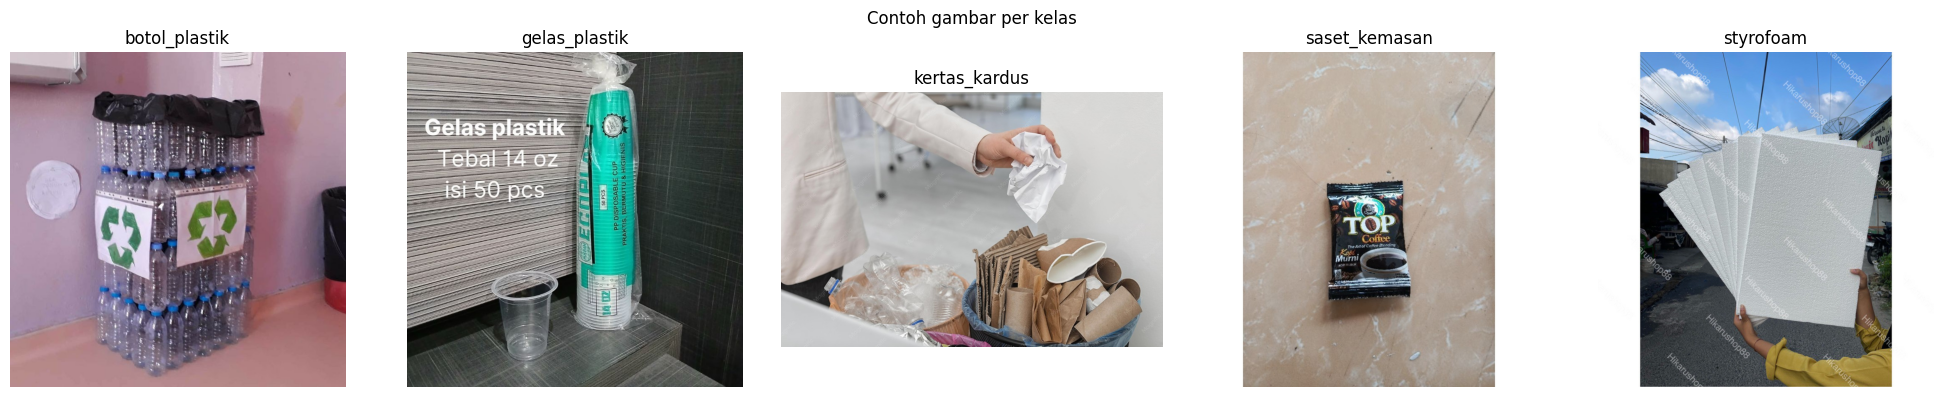

In [33]:
# Debug singkat: pastikan satu batch bisa dimuat
images, labels, paths = next(iter(train_loader))
print("Batch image shape:", tuple(images.shape))
print("Labels (8 pertama):", labels[:8].tolist(), [idx_to_label[int(l)] for l in labels[:8]])
print(f"Range tensor: [{images.min():.3f}, {images.max():.3f}]")

# Contoh gambar tiap kelas
fig, axes = plt.subplots(1, num_classes, figsize=(4*num_classes, 4))
for ax, (i, cls) in zip(axes, enumerate(class_names)):
    p = next(p for p, l in samples if l == i)
    ax.imshow(Image.open(p).convert('RGB'))
    ax.set_title(cls)
    ax.axis('off')
plt.suptitle('Contoh gambar per kelas')
plt.tight_layout()
plt.show()

## 6. Fungsi Pelatihan dan Validasi

`validate` menghitung **Macro-F1** (rata-rata F1 kelima kelas), metrik yang dipakai untuk menilai tugas, selain loss dan akurasi.

In [34]:
def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0

    pbar = tqdm(dataloader, desc='Training')
    for batch_idx, (inputs, targets, _) in enumerate(pbar):
        inputs, targets = inputs.to(device), targets.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()
        correct += outputs.argmax(1).eq(targets).sum().item()
        total += targets.size(0)
        pbar.set_postfix({'loss': total_loss/(batch_idx+1), 'acc': 100.*correct/total})

    return total_loss/len(dataloader), 100.*correct/total

@torch.no_grad()
def validate(model, dataloader, criterion, device):
    model.eval()
    total_loss = 0.0
    all_preds, all_targets = [], []

    for inputs, targets, _ in tqdm(dataloader, desc='Validation'):
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = model(inputs)
        total_loss += criterion(outputs, targets).item()
        all_preds.extend(outputs.argmax(1).cpu().numpy())
        all_targets.extend(targets.cpu().numpy())

    all_preds, all_targets = np.array(all_preds), np.array(all_targets)
    acc = 100. * (all_preds == all_targets).mean()
    macro_f1 = f1_score(all_targets, all_preds, average='macro')
    return total_loss/len(dataloader), acc, macro_f1

@torch.no_grad()
def predict(model, dataloader, device):
    # Kembalikan preds, labels, probs, paths untuk analisis detail
    model.eval()
    preds, labels, probs, paths = [], [], [], []
    for inputs, targets, p in tqdm(dataloader, desc='Predicting'):
        out = torch.softmax(model(inputs.to(device)), dim=1)
        preds.extend(out.argmax(1).cpu().numpy())
        labels.extend(targets.numpy())
        probs.extend(out.cpu().numpy())
        paths.extend(p)
    return np.array(preds), np.array(labels), np.array(probs), paths

## 7. Membangun dan Melatih Model

- Model: EfficientNet-B3 pretrained ImageNet lewat `get_model(pretrained=True)` (arsitektur dan classifier identik dengan `submission/model.py`)
- Loss: CrossEntropy dengan **label smoothing** (label dataset mengandung sedikit noise) dan **class weight** ringan (kelas tidak seimbang, sedangkan Macro-F1 memberi bobot sama pada tiap kelas)
- Optimizer: AdamW dengan learning rate berbeda untuk backbone dan classifier, scheduler CosineAnnealingLR
- **Model terbaik dipilih berdasarkan Macro-F1 validasi** (tie-break: val loss lebih kecil) dan disimpan sebagai **state_dict murni** ke `submission/model.pth`, sesuai kontrak `torch.save(model.state_dict(), "submission/model.pth")`

In [31]:
model = sub_model.get_model(pretrained=True).to(device)

# Class weight ringan (akar dari inverse frequency), dinormalisasi ke rata-rata 1
class_weights = None
if USE_CLASS_WEIGHTS:
    counts = np.bincount([l for _, l in train_samples], minlength=num_classes)
    w = (counts.sum() / (num_classes * counts)) ** 0.5
    w = w / w.mean()
    class_weights = torch.tensor(w, dtype=torch.float32).to(device)
    print("Class weights:", {class_names[i]: round(float(w[i]), 3) for i in range(num_classes)})

criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=label_smoothing)
optimizer = torch.optim.AdamW([
    {'params': model.features.parameters(),   'lr': lr_backbone},
    {'params': model.classifier.parameters(), 'lr': lr_head},
], weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)

SUBMISSION_WEIGHTS = 'submission/model.pth'
RETRAIN = True   # False = lewati latihan dan muat submission/model.pth yang sudah ada

history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'val_f1': []}
best_f1, best_loss, best_epoch = -1.0, float('inf'), 0

if os.path.exists(SUBMISSION_WEIGHTS) and not RETRAIN:
    model.load_state_dict(torch.load(SUBMISSION_WEIGHTS, map_location=device))
    _, _, best_f1 = validate(model, val_loader, criterion, device)
    print(f"Bobot dimuat dari {SUBMISSION_WEIGHTS}. Macro-F1 my_val: {best_f1:.4f}")
else:
    for epoch in range(num_epochs):
        lrs = [g['lr'] for g in optimizer.param_groups]
        print(f"\nEpoch {epoch+1}/{num_epochs}  (lr backbone={lrs[0]:.6f}, head={lrs[1]:.6f})")
        tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        va_loss, va_acc, va_f1 = validate(model, val_loader, criterion, device)
        scheduler.step()

        history['train_loss'].append(tr_loss); history['train_acc'].append(tr_acc)
        history['val_loss'].append(va_loss);   history['val_acc'].append(va_acc)
        history['val_f1'].append(va_f1)
        print(f"Train loss {tr_loss:.4f} acc {tr_acc:.2f}% | "
              f"Val loss {va_loss:.4f} acc {va_acc:.2f}% | Macro-F1 {va_f1:.4f}")

        # Pilih model terbaik berdasarkan Macro-F1 (tie-break: val loss)
        if va_f1 > best_f1 or (va_f1 == best_f1 and va_loss < best_loss):
            best_f1, best_loss, best_epoch = va_f1, va_loss, epoch + 1
            # state_dict murni (tensor di CPU) sesuai kontrak submission
            torch.save({k: v.detach().cpu() for k, v in model.state_dict().items()}, SUBMISSION_WEIGHTS)
            print(f"  -> Model terbaik disimpan ke {SUBMISSION_WEIGHTS} (Macro-F1 {best_f1:.4f})")

    # muat kembali model terbaik untuk evaluasi
    model.load_state_dict(torch.load(SUBMISSION_WEIGHTS, map_location=device))

model.eval()
print(f"\nBest Macro-F1 (my_val): {best_f1:.4f}" + (f" pada epoch {best_epoch}" if best_epoch else ""))

Class weights: {'botol_plastik': 1.008, 'gelas_plastik': 1.009, 'kertas_kardus': 1.206, 'saset_kemasan': 0.888, 'styrofoam': 0.889}

Epoch 1/20  (lr backbone=0.000100, head=0.001000)


Validation: 100%|██████████| 18/18 [00:04<00:00,  4.39it/s]


Train loss 0.7707 acc 78.75% | Val loss 0.5252 acc 89.66% | Macro-F1 0.8956
  -> Model terbaik disimpan ke submission/model.pth (Macro-F1 0.8956)

Epoch 2/20  (lr backbone=0.000099, head=0.000994)


Validation: 100%|██████████| 18/18 [00:04<00:00,  4.29it/s]


Train loss 0.5184 acc 89.06% | Val loss 0.4810 acc 92.92% | Macro-F1 0.9253
  -> Model terbaik disimpan ke submission/model.pth (Macro-F1 0.9253)

Epoch 3/20  (lr backbone=0.000098, head=0.000976)


...

Train loss 0.2776 acc 99.68% | Val loss 0.3475 acc 96.19% | Macro-F1 0.9614

Epoch 19/20  (lr backbone=0.000002, head=0.000024)


Validation: 100%|██████████| 18/18 [00:04<00:00,  4.22it/s]


Train loss 0.2800 acc 99.09% | Val loss 0.3503 acc 95.83% | Macro-F1 0.9578

Epoch 20/20  (lr backbone=0.000001, head=0.000006)


Validation: 100%|██████████| 18/18 [00:04<00:00,  4.23it/s]


Train loss 0.2815 acc 99.32% | Val loss 0.3517 acc 95.64% | Macro-F1 0.9555

Best Macro-F1 (my_val): 0.9652 pada epoch 12


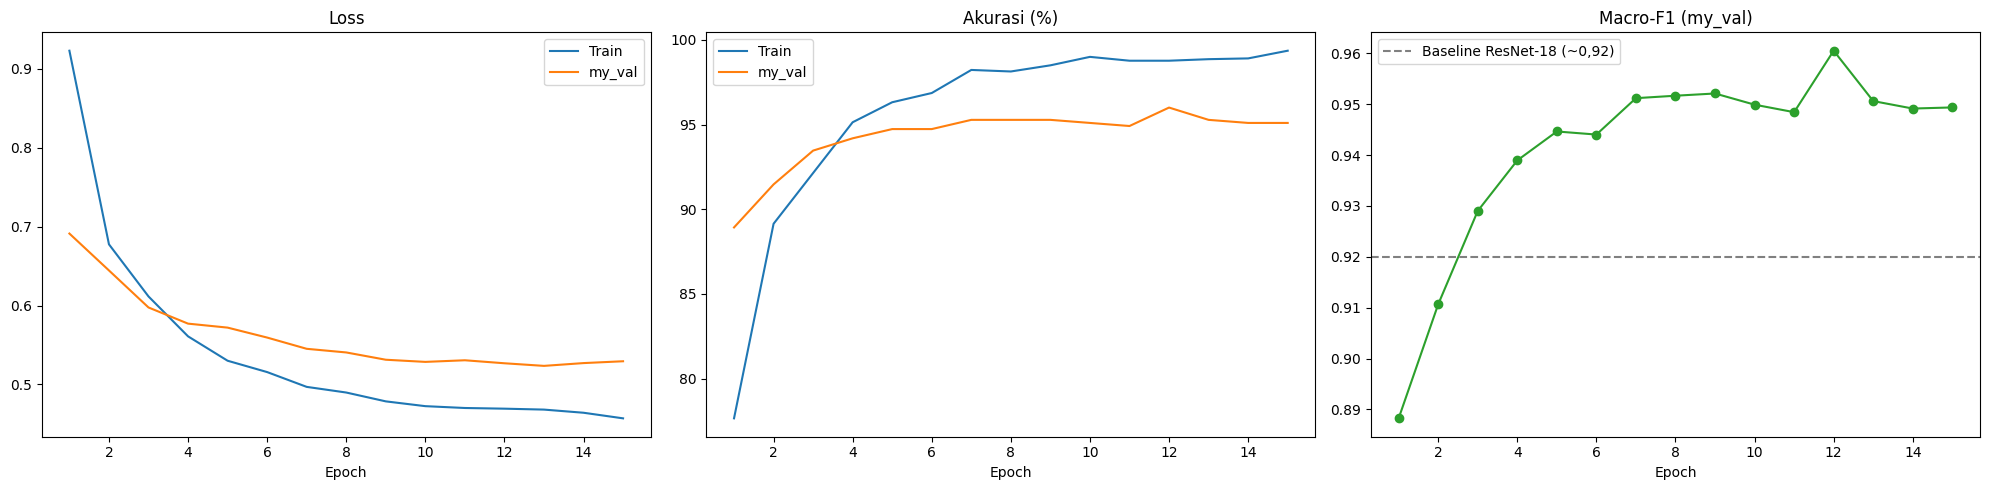

In [22]:
# Kurva loss, akurasi, dan Macro-F1 (jika pelatihan dijalankan pada sesi ini)
if len(history['train_loss']) > 0:
    ep = range(1, len(history['train_loss']) + 1)
    fig, ax = plt.subplots(1, 3, figsize=(20, 5))
    ax[0].plot(ep, history['train_loss'], label='Train'); ax[0].plot(ep, history['val_loss'], label='my_val')
    ax[0].set_title('Loss'); ax[0].set_xlabel('Epoch'); ax[0].legend()
    ax[1].plot(ep, history['train_acc'], label='Train'); ax[1].plot(ep, history['val_acc'], label='my_val')
    ax[1].set_title('Akurasi (%)'); ax[1].set_xlabel('Epoch'); ax[1].legend()
    ax[2].plot(ep, history['val_f1'], color='tab:green', marker='o')
    ax[2].axhline(0.92, color='gray', linestyle='--', label='Baseline ResNet-18 (~0,92)')
    ax[2].set_title('Macro-F1 (my_val)'); ax[2].set_xlabel('Epoch'); ax[2].legend()
    plt.tight_layout()
    plt.show()

In [35]:
model = sub_model.get_model(pretrained=True).to(device)

# Class weights: square root of inverse frequency, normalized to mean 1
class_weights = None
if USE_CLASS_WEIGHTS:
    counts = np.bincount(
        [l for _, l in train_samples],
        minlength=num_classes
    )
    w = (counts.sum() / (num_classes * counts)) ** 0.5
    w = w / w.mean()

    class_weights = torch.tensor(
        w, dtype=torch.float32
    ).to(device)

    print("Class weights:", {
        class_names[i]: round(float(w[i]), 3)
        for i in range(num_classes)
    })

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=label_smoothing
)

optimizer = torch.optim.AdamW([
    {'params': model.features.parameters(), 'lr': lr_backbone},
    {'params': model.classifier.parameters(), 'lr': lr_head},
], weight_decay=1e-4)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=num_epochs
)

SUBMISSION_WEIGHTS = 'submission/model.pth'
RETRAIN = True

# Early stopping configuration
patience = 5
min_delta = 0.001

history = {
    'train_loss': [],
    'train_acc': [],
    'val_loss': [],
    'val_acc': [],
    'val_f1': []
}

best_f1 = -1.0
best_loss = float('inf')
best_epoch = 0
epochs_without_improvement = 0

if os.path.exists(SUBMISSION_WEIGHTS) and not RETRAIN:
    model.load_state_dict(
        torch.load(SUBMISSION_WEIGHTS, map_location=device)
    )

    _, _, best_f1 = validate(
        model, val_loader, criterion, device
    )

    print(
        f"Weights loaded from {SUBMISSION_WEIGHTS}. "
        f"Validation Macro-F1: {best_f1:.4f}"
    )

else:
    for epoch in range(num_epochs):
        lrs = [g['lr'] for g in optimizer.param_groups]

        print(
            f"\nEpoch {epoch + 1}/{num_epochs} "
            f"(lr backbone={lrs[0]:.6f}, head={lrs[1]:.6f})"
        )

        tr_loss, tr_acc = train_one_epoch(
            model, train_loader, criterion, optimizer, device
        )

        va_loss, va_acc, va_f1 = validate(
            model, val_loader, criterion, device
        )

        # Store metrics for later plotting
        history['train_loss'].append(tr_loss)
        history['train_acc'].append(tr_acc)
        history['val_loss'].append(va_loss)
        history['val_acc'].append(va_acc)
        history['val_f1'].append(va_f1)

        scheduler.step()

        # Improvement means Macro-F1 increases by min_delta.
        # If F1 is effectively tied, lower validation loss wins.
        improved = (
            va_f1 > best_f1 + min_delta
            or (
                abs(va_f1 - best_f1) <= min_delta
                and va_loss < best_loss
            )
        )

        if improved:
            best_f1 = va_f1
            best_loss = va_loss
            best_epoch = epoch + 1
            epochs_without_improvement = 0

            # Save best state_dict as CPU tensors
            torch.save(
                {
                    k: v.detach().cpu()
                    for k, v in model.state_dict().items()
                },
                SUBMISSION_WEIGHTS
            )

            print(
                f"  -> Best model saved: {SUBMISSION_WEIGHTS} "
                f"(Macro-F1={best_f1:.4f}, "
                f"val_loss={best_loss:.4f})"
            )

        else:
            epochs_without_improvement += 1

            print(
                f"  -> No meaningful improvement: "
                f"{epochs_without_improvement}/{patience}"
            )

        # Stop if validation performance has stalled
        if epochs_without_improvement >= patience:
            print(
                f"\nEarly stopping at epoch {epoch + 1}. "
                f"Best epoch: {best_epoch}, "
                f"best Macro-F1: {best_f1:.4f}"
            )
            break

    # Restore best checkpoint before final evaluation
    model.load_state_dict(
        torch.load(SUBMISSION_WEIGHTS, map_location=device)
    )

model.eval()

print(
    f"\nBest validation Macro-F1: {best_f1:.4f}"
    + (f" at epoch {best_epoch}" if best_epoch else "")
)


Class weights: {'botol_plastik': 1.008, 'gelas_plastik': 1.009, 'kertas_kardus': 1.206, 'saset_kemasan': 0.888, 'styrofoam': 0.889}

Epoch 1/20 (lr backbone=0.000100, head=0.001000)


Validation: 100%|██████████| 18/18 [00:04<00:00,  4.48it/s]


  -> Best model saved: submission/model.pth (Macro-F1=0.8956, val_loss=0.5251)

Epoch 2/20 (lr backbone=0.000099, head=0.000994)


Validation: 100%|██████████| 18/18 [00:04<00:00,  4.38it/s]


  -> Best model saved: submission/model.pth (Macro-F1=0.9248, val_loss=0.4794)

Epoch 3/20 (lr backbone=0.000098, head=0.000976)


...

  -> No meaningful improvement: 3/5

Epoch 19/20 (lr backbone=0.000002, head=0.000024)


Validation: 100%|██████████| 18/18 [00:04<00:00,  4.30it/s]


  -> No meaningful improvement: 4/5

Epoch 20/20 (lr backbone=0.000001, head=0.000006)


Validation: 100%|██████████| 18/18 [00:04<00:00,  4.17it/s]


  -> No meaningful improvement: 5/5

Early stopping at epoch 20. Best epoch: 15, best Macro-F1: 0.9626

Best validation Macro-F1: 0.9626 at epoch 15


### Ringkasan Arsitektur Model

In [36]:
try:
    from torchinfo import summary
except ImportError:
    !pip install torchinfo
    from torchinfo import summary

model_summary = summary(model, input_size=(batch_size, 3, sub_model.IMG_SIZE, sub_model.IMG_SIZE),
                        col_names=["input_size", "output_size", "num_params"],
                        col_width=20, row_settings=["var_names"], depth=2)

print(f"\nTotal Parameters: {model_summary.total_params:,}")
print(f"Estimasi ukuran bobot: {model_summary.total_params * 4 / (1024*1024):.2f} MB")


Total Parameters: 12,277,293
Estimasi ukuran bobot: 46.83 MB


## 8. Evaluasi pada `my_val`

Metrik utama: **Macro-F1**. Selain itu: confusion matrix, classification report (F1 per kelas), ROC/AUC, dan contoh prediksi.

Predicting: 100%|██████████| 18/18 [00:04<00:00,  4.18it/s]


Total sampel my_val : 551
Akurasi             : 96.37%
Macro-F1            : 0.9626   (baseline ResNet-18 ~0,92)


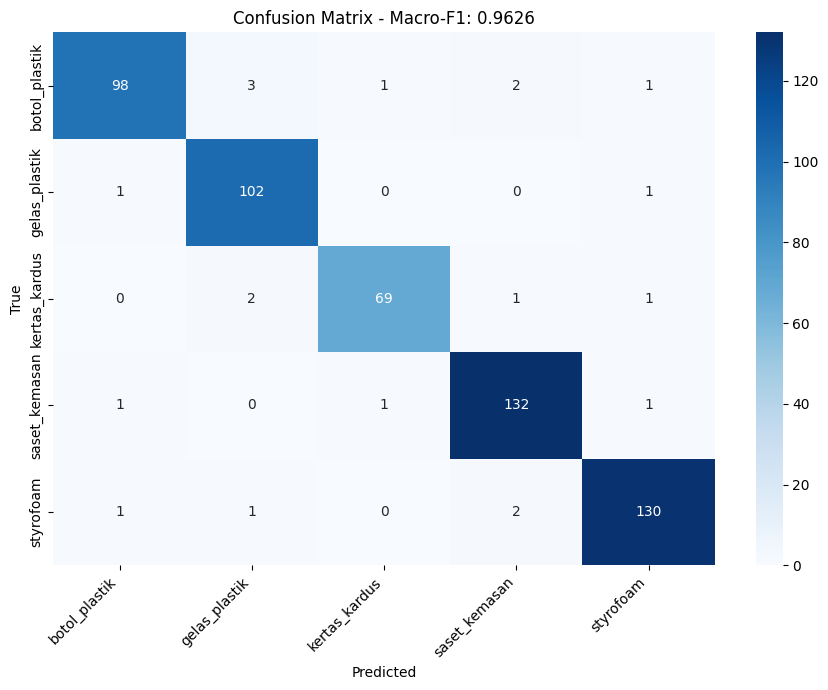


Classification Report (F1 per kelas):
               precision    recall  f1-score   support

botol_plastik     0.9703    0.9333    0.9515       105
gelas_plastik     0.9444    0.9808    0.9623       104
kertas_kardus     0.9718    0.9452    0.9583        73
saset_kemasan     0.9635    0.9778    0.9706       135
    styrofoam     0.9701    0.9701    0.9701       134

     accuracy                         0.9637       551
    macro avg     0.9640    0.9614    0.9626       551
 weighted avg     0.9639    0.9637    0.9636       551

Hasil detail disimpan ke 'detailed_val_results.csv'


In [37]:
val_preds, val_labels, val_probs, val_paths = predict(model, val_loader, device)

accuracy = (val_preds == val_labels).mean() * 100
macro_f1 = f1_score(val_labels, val_preds, average='macro')

print(f"{'='*50}")
print(f"Total sampel my_val : {len(val_labels)}")
print(f"Akurasi             : {accuracy:.2f}%")
print(f"Macro-F1            : {macro_f1:.4f}   (baseline ResNet-18 ~0,92)")
print(f"{'='*50}")

# Confusion matrix
cm = confusion_matrix(val_labels, val_preds)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title(f'Confusion Matrix - Macro-F1: {macro_f1:.4f}')
plt.xlabel('Predicted'); plt.ylabel('True')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

print("\nClassification Report (F1 per kelas):")
print(classification_report(val_labels, val_preds, target_names=class_names, digits=4))

pd.DataFrame({
    'path': val_paths,
    'predicted': [idx_to_label[p] for p in val_preds],
    'actual': [idx_to_label[l] for l in val_labels],
    'correct': val_preds == val_labels,
}).to_csv('detailed_val_results.csv', index=False)
print("Hasil detail disimpan ke 'detailed_val_results.csv'")

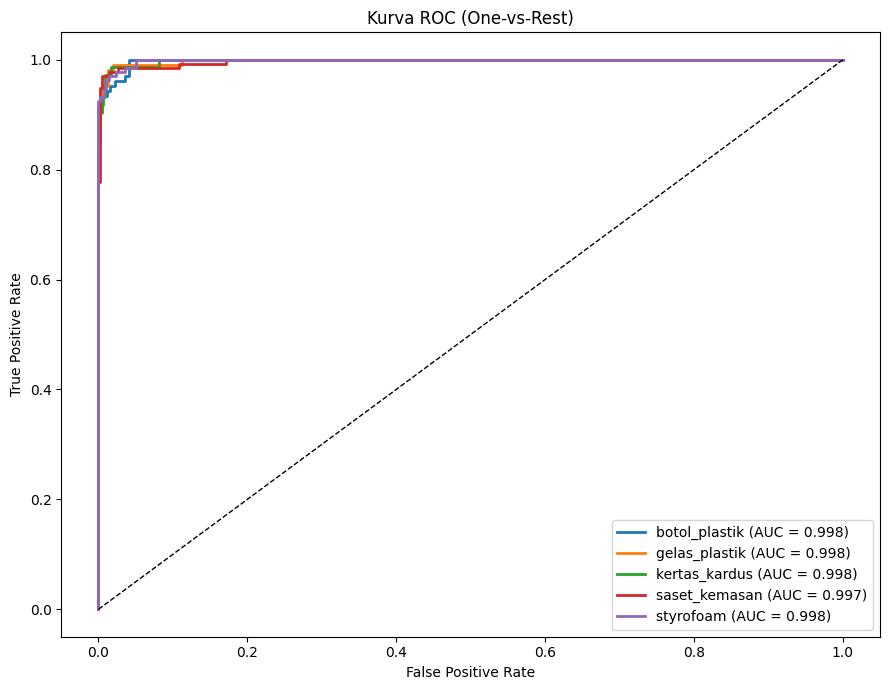

In [38]:
# Kurva ROC (one-vs-rest) dan AUC per kelas
y_bin = label_binarize(val_labels, classes=list(range(num_classes)))

plt.figure(figsize=(9, 7))
colors = cycle(['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple'])
for i, color in zip(range(num_classes), colors):
    fpr, tpr, _ = roc_curve(y_bin[:, i], val_probs[:, i])
    plt.plot(fpr, tpr, color=color, lw=2, label=f'{class_names[i]} (AUC = {auc(fpr, tpr):.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title('Kurva ROC (One-vs-Rest)')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

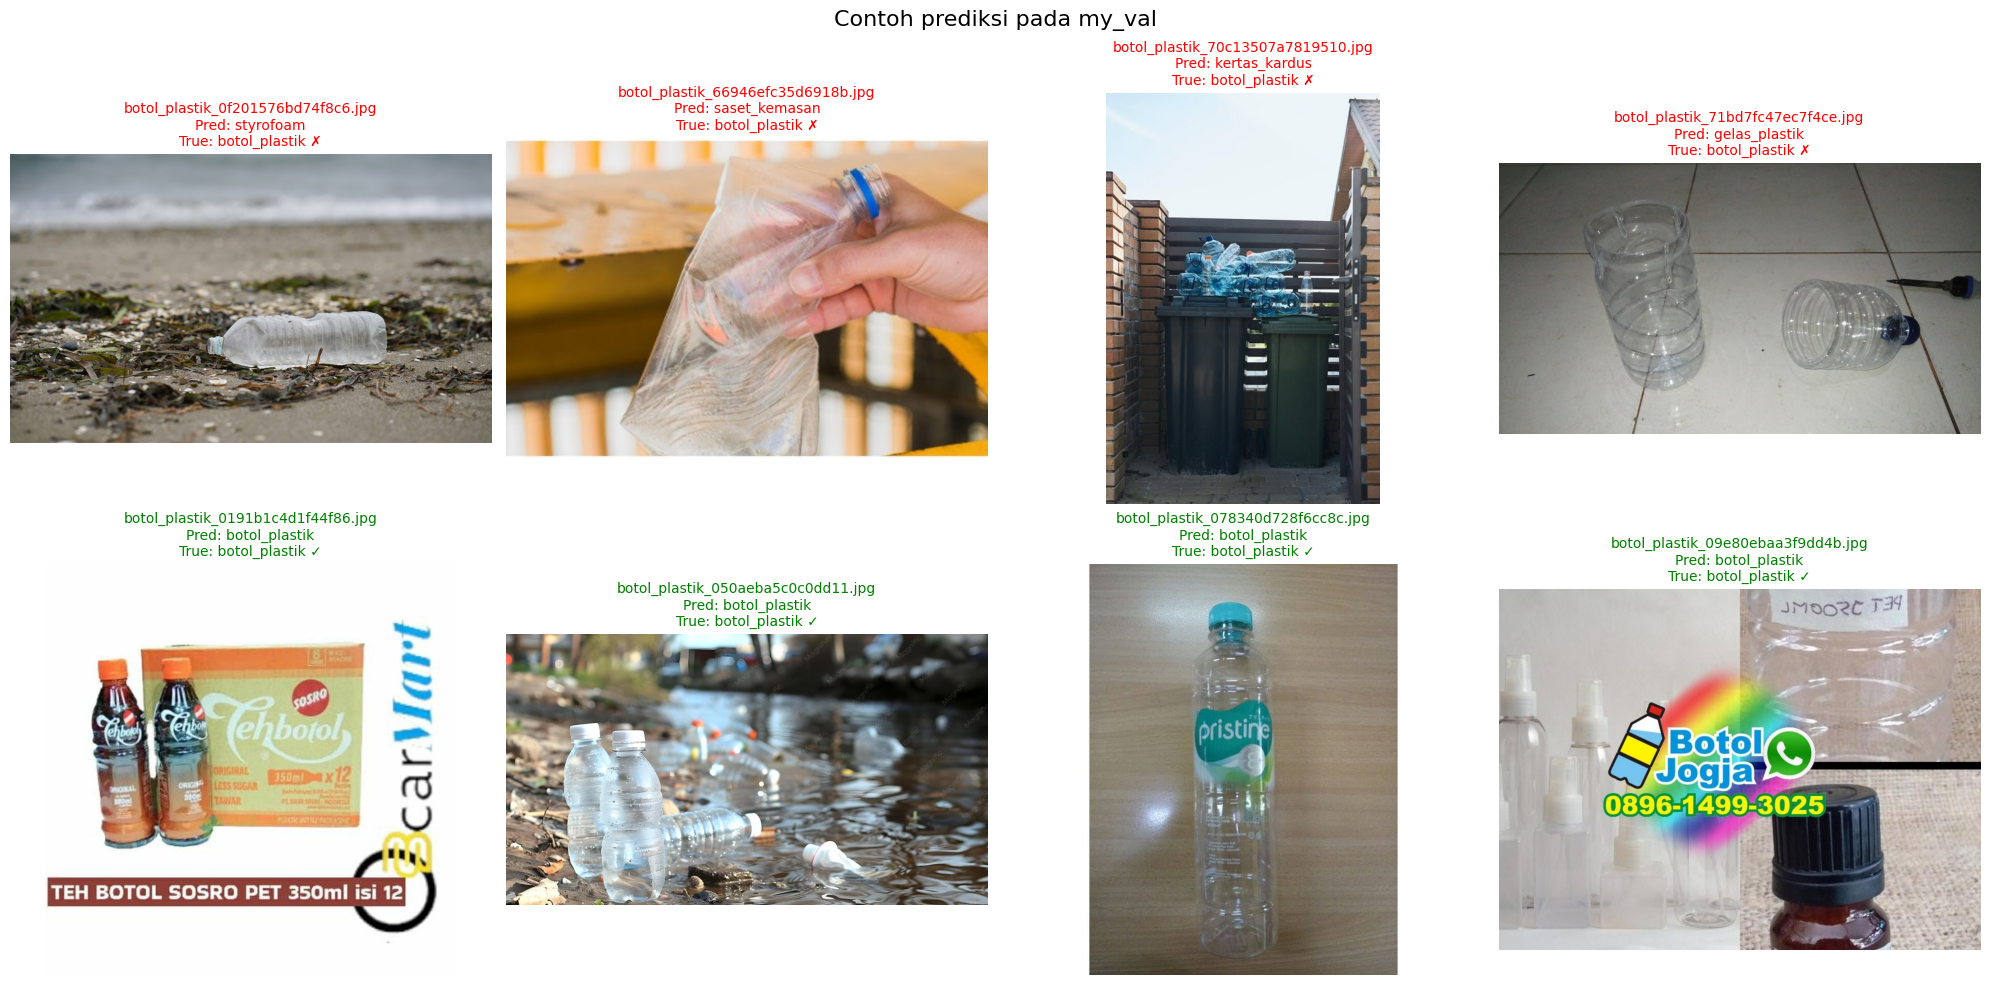

In [39]:
# Contoh prediksi (benar = hijau, salah = merah); salah diprioritaskan
wrong_idx = np.where(val_preds != val_labels)[0]
right_idx = np.where(val_preds == val_labels)[0]
show_idx = list(wrong_idx[:4]) + list(right_idx[:8 - min(4, len(wrong_idx))])

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.ravel()
for ax, i in zip(axes, show_idx):
    ax.imshow(Image.open(val_paths[i]).convert('RGB'))
    ok = val_preds[i] == val_labels[i]
    ax.set_title(f"{os.path.basename(val_paths[i])}\nPred: {idx_to_label[val_preds[i]]}\n"
                 f"True: {idx_to_label[val_labels[i]]} {'✓' if ok else '✗'}",
                 color='green' if ok else 'red', fontsize=10)
    ax.axis('off')
for ax in axes[len(show_idx):]:
    ax.axis('off')
plt.suptitle('Contoh prediksi pada my_val', fontsize=16, y=0.98)
plt.tight_layout()
plt.show()

## 9. Verifikasi Submission (simulasi `evaluate.py`)

Sel ini meniru cara `evaluate.py` bekerja, memakai **hanya** isi folder `submission/`:
1. `get_model()` tanpa argumen (tanpa unduh bobot) lalu `load_state_dict` dari `model.pth`
2. `get_transform()` pada gambar PIL RGB dari `my_val/`
3. Macro-F1 harus sama dengan hasil evaluasi di atas
4. Cek batas teknis: ukuran `model.pth` ≤ 500 MB (>100 MB harus lewat GitHub Release / Git LFS), waktu evaluasi ≤ 15 menit

Jika file `evaluate.py` resmi dari starter kit ada di folder kerja, sel ini juga menjalankannya.

In [15]:
t0 = time.time()

check_model = sub_model.get_model()                        # tanpa pretrained / tanpa unduhan
state = torch.load('submission/model.pth', map_location='cpu')
assert isinstance(state, dict) and 'model_state_dict' not in state, \
    "model.pth harus state_dict murni, bukan dict checkpoint"
check_model.load_state_dict(state)                          # error jika kunci tidak cocok
check_model = check_model.to(device).eval()
tf = sub_model.get_transform()

preds, labels = [], []
batch_x, batch_y = [], []
def flush():
    global batch_x, batch_y
    if batch_x:
        with torch.no_grad():
            out = check_model(torch.stack(batch_x).to(device))
        preds.extend(out.argmax(1).cpu().numpy()); labels.extend(batch_y)
        batch_x, batch_y = [], []

for path, lbl in tqdm(val_samples, desc='Simulasi evaluate.py'):
    batch_x.append(tf(Image.open(path).convert('RGB'))); batch_y.append(lbl)
    if len(batch_x) == 64:
        flush()
flush()

check_f1 = f1_score(labels, preds, average='macro')
elapsed = time.time() - t0
size_mb = os.path.getsize('submission/model.pth') / (1024 * 1024)

print(f"Macro-F1 simulasi : {check_f1:.4f} (hasil evaluasi di atas: {macro_f1:.4f}, selisih {abs(check_f1 - macro_f1):.6f})")
print(f"Output model       : logits [batch, {check_model(torch.zeros(1,3,sub_model.IMG_SIZE,sub_model.IMG_SIZE).to(device)).shape[1]}]")
print(f"Ukuran model.pth   : {size_mb:.1f} MB  (batas 500 MB; >100 MB -> GitHub Release / Git LFS)")
print(f"Waktu evaluasi     : {elapsed:.1f} detik untuk {len(val_samples)} gambar (batas 15 menit untuk ~740 gambar)")

if os.path.exists('evaluate.py'):
    print("\nMenjalankan evaluate.py resmi...")
    res = subprocess.run([sys.executable, 'evaluate.py', '--submission', './submission', '--data', './my_val'],
                         capture_output=True, text=True)
    print(res.stdout); print(res.stderr)
else:
    print("\nevaluate.py belum ada di folder kerja. Salin dari starter kit lalu jalankan:")
    print("  python evaluate.py --submission ./submission --data ./my_val")

Simulasi evaluate.py: 100%|██████████| 551/551 [00:08<00:00, 68.82it/s]


Macro-F1 simulasi : 0.9609 (hasil evaluasi di atas: 0.9609, selisih 0.000000)
Output model       : logits [batch, 5]
Ukuran model.pth   : 47.3 MB  (batas 500 MB; >100 MB -> GitHub Release / Git LFS)
Waktu evaluasi     : 8.6 detik untuk 551 gambar (batas 15 menit untuk ~740 gambar)

evaluate.py belum ada di folder kerja. Salin dari starter kit lalu jalankan:
  python evaluate.py --submission ./submission --data ./my_val


## 10. Sebelum Commit

Dataset tidak boleh masuk repo publik. Sel di bawah menambahkan aturan ke `.gitignore` agar `my_val/`, `train/`, dan arsip dataset tidak ikut ter-commit.

Checklist repo (di luar notebook): `README.md` (nama kelompok, **nama lengkap + NIM semua anggota**, ringkasan pendekatan, sumber data tambahan jika ada, cara reproduksi), salinan `evaluate.py`, `submission/model.py`, dan `submission/model.pth` (jika >100 MB gunakan GitHub Release atau Git LFS dan tulis tautannya di README). Commit secara berkala.

In [40]:
rules = ['my_val/', 'train/', 'dataset_mahasiswa/', '*.zip', 'detailed_val_results.csv']
existing = open('.gitignore').read().splitlines() if os.path.exists('.gitignore') else []
to_add = [r for r in rules if r not in existing]
if to_add:
    with open('.gitignore', 'a') as f:
        f.write(('\n' if existing and existing[-1] != '' else '') + '\n'.join(to_add) + '\n')
print(".gitignore diperbarui:", to_add if to_add else "sudah lengkap")

.gitignore diperbarui: sudah lengkap


In [17]:
# Daftar paket lingkungan pelatihan (untuk dokumentasi; submission/requirements.txt cukup torch, torchvision, pillow, numpy yang sudah tersedia)
!pip freeze > requirements_training.txt